Description...

In [2]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/Muon_Veto/')

from utilities import *

%load_ext autoreload
%autoreload 2

# Unconnected Pins

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261104-114128.h5
Loaded 10,670 events over 167.25 seconds.
Total DAQ Trigger Rate: 63.8 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 236.00           | 60.79            | 539.93              
Ch 1       | 10     | 233.00           | 20.76            | 336.78              
Ch 2       | 10     | 251.00           | 68.20            | 592.00              
Ch 3       | 10     | 231.00           | 23.72            | 349.61              
Ch 4       | 10     | 213.00           | 26.69            | 346.43              
Ch 5       | 10     | 225.00           | 26.69            | 358.43              
Ch 6       | 10     | 223.00           | 16.31            | 304.54              
Ch 7       | 10     | 216.00           | 14.83            | 290.1

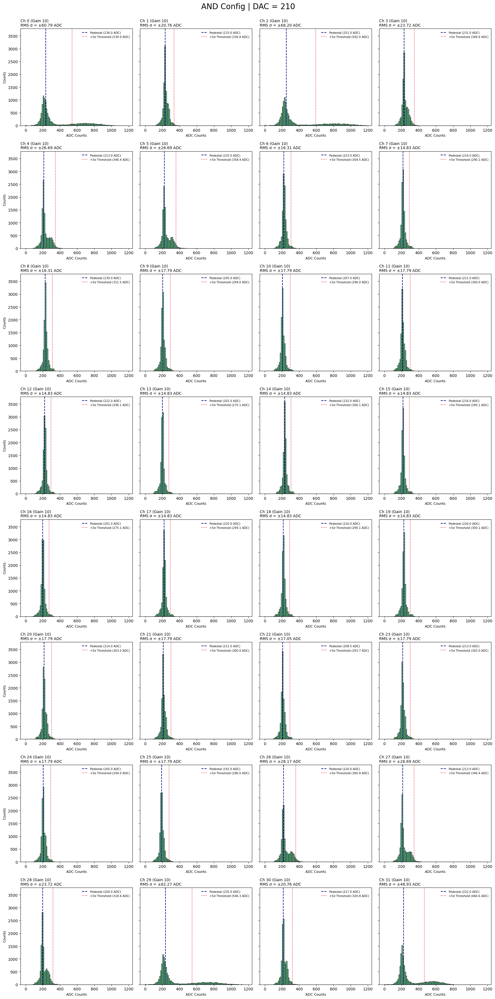

In [11]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261104-114128.h5"

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [i for i in range(32)]
# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Threshold':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas = {}
ch_threshold = {}

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    ch_threshold[ch] = med + 5 * sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {med + 5 * sigma:<20.2f}")

# Characteristic electronic noise per unit gain
reference_pedestal = float(np.median(list(free_pedestals.values())))
reference_sigma = float(np.median(list(free_sigmas.values())))
reference_threshold = float(np.median(list(ch_threshold.values())))
print("-" * 78)
print(f"For Gain = 10")
print(f"--> Median Pedestal: {reference_pedestal:.2f} ADC counts")
print(f"--> Median Sigma: ±{reference_sigma:.2f} ADC counts")
print (f"--> Median Threshold: {reference_threshold:.2f} ADC counts")
print("=" * 78 + "\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================
free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

max_x = np.max(list(ch_threshold.values()))
for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    thresh = ch_threshold[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=100, range=(0, 2.0*max_x), color='mediumseagreen', alpha=0.75, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f} ADC)')
    ax.axvline(thresh, color='crimson', linestyle=':', label=f'+5σ Threshold ({med + 5*sig:.1f} ADC)')

    # ax.set_xlim(0, max_x*1.05)
    # ax.set_yscale('log')
    
    ax.set_title(f"Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, loc='left')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Counts", fontsize=9)
    ax.legend(fontsize=7.5,  loc='upper right', facecolor='none', framealpha=0)

plt.suptitle("AND Config | DAC = 210", fontsize=20, y=1.0)
plt.tight_layout()

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261104-120152.h5
Loaded 32,531 events over 56.20 seconds.
Total DAQ Trigger Rate: 578.8 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 205.00           | 11.86            | 264.30              
Ch 1       | 10     | 216.00           | 11.86            | 275.30              
Ch 2       | 10     | 210.00           | 11.86            | 269.30              
Ch 3       | 10     | 213.00           | 11.86            | 272.30              
Ch 4       | 10     | 199.00           | 14.83            | 273.13              
Ch 5       | 10     | 211.00           | 14.83            | 285.13              
Ch 6       | 10     | 212.00           | 13.34            | 278.72              
Ch 7       | 10     | 205.00           | 13.34            | 271.7

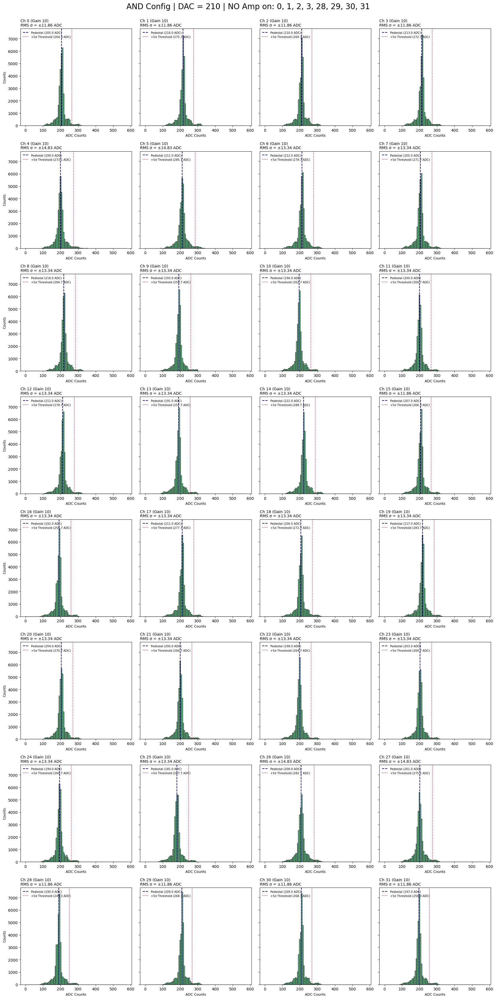

In [10]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261104-120152.h5"

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [i for i in range(32)]
# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Threshold':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas = {}
ch_threshold = {}

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    ch_threshold[ch] = med + 5 * sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {med + 5 * sigma:<20.2f}")

# Characteristic electronic noise per unit gain
reference_pedestal = float(np.median(list(free_pedestals.values())))
reference_sigma = float(np.median(list(free_sigmas.values())))
reference_threshold = float(np.median(list(ch_threshold.values())))
print("-" * 78)
print(f"For Gain = 10")
print(f"--> Median Pedestal: {reference_pedestal:.2f} ADC counts")
print(f"--> Median Sigma: ±{reference_sigma:.2f} ADC counts")
print (f"--> Median Threshold: {reference_threshold:.2f} ADC counts")
print("=" * 78 + "\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================
free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

max_x = np.max(list(ch_threshold.values()))
for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    thresh = ch_threshold[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=100, range=(0, 2.0*max_x), color='mediumseagreen', alpha=0.75, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f} ADC)')
    ax.axvline(thresh, color='crimson', linestyle=':', label=f'+5σ Threshold ({med + 5*sig:.1f} ADC)')

    # ax.set_xlim(0, max_x*1.05)
    # ax.set_yscale('log')
    
    ax.set_title(f"Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, loc='left')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Counts", fontsize=9)
    ax.legend(fontsize=7.5,  loc='upper left', facecolor='none', framealpha=0)

plt.suptitle("AND Config | DAC = 210 | NO Amp on: 0, 1, 2, 3, 28, 29, 30, 31", fontsize=20, y=1.0)
plt.tight_layout()

# Trial 0

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module1/muons_20261103-162257.h5
Loaded 104,701 events over 176.20 seconds.
Total DAQ Trigger Rate: 594.2 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 22      | 10     | 197.00           | 14.83            | 271.13              
Ch 23      | 10     | 201.00           | 14.83            | 275.13              
Ch 24      | 10     | 192.00           | 14.83            | 266.13              
Ch 25      | 10     | 179.00           | 14.83            | 253.13              
Ch 26      | 10     | 205.00           | 17.79            | 293.96              
Ch 27      | 10     | 198.00           | 17.79            | 286.96              
Ch 28      | 10     | 186.00           | 16.31            | 267.54              
Ch 29      | 10     | 205.00           | 37.06            | 390

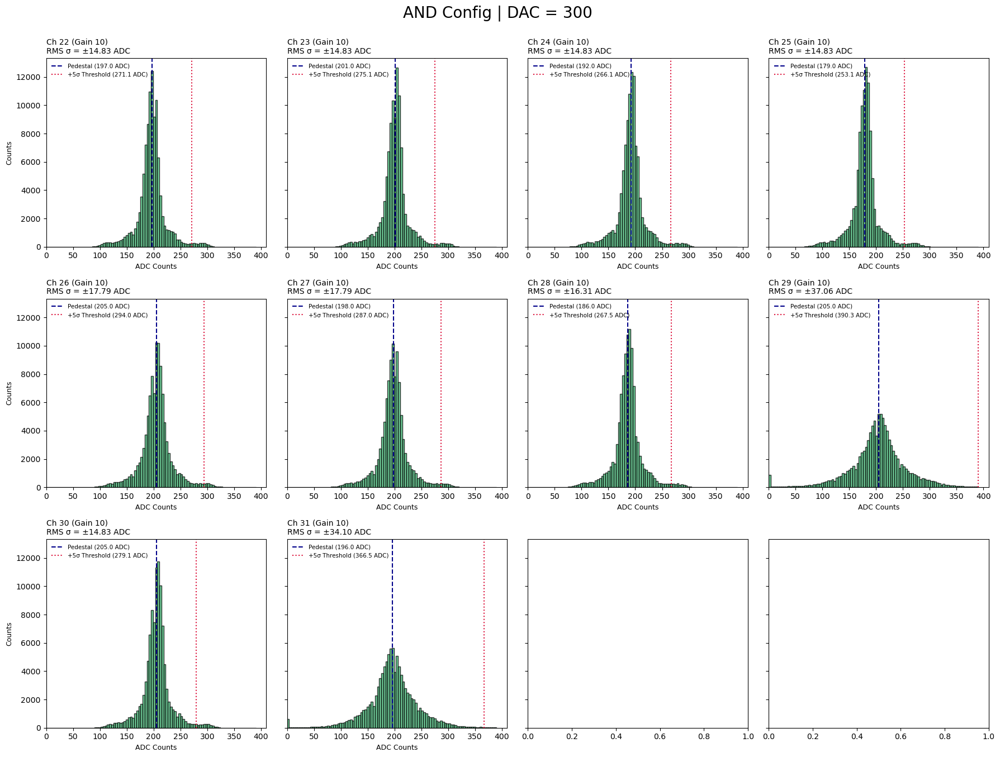

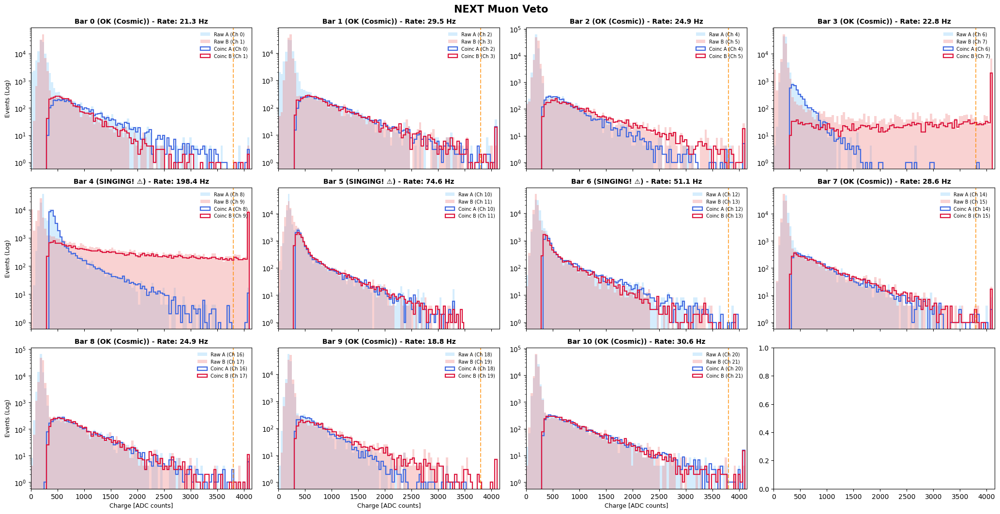

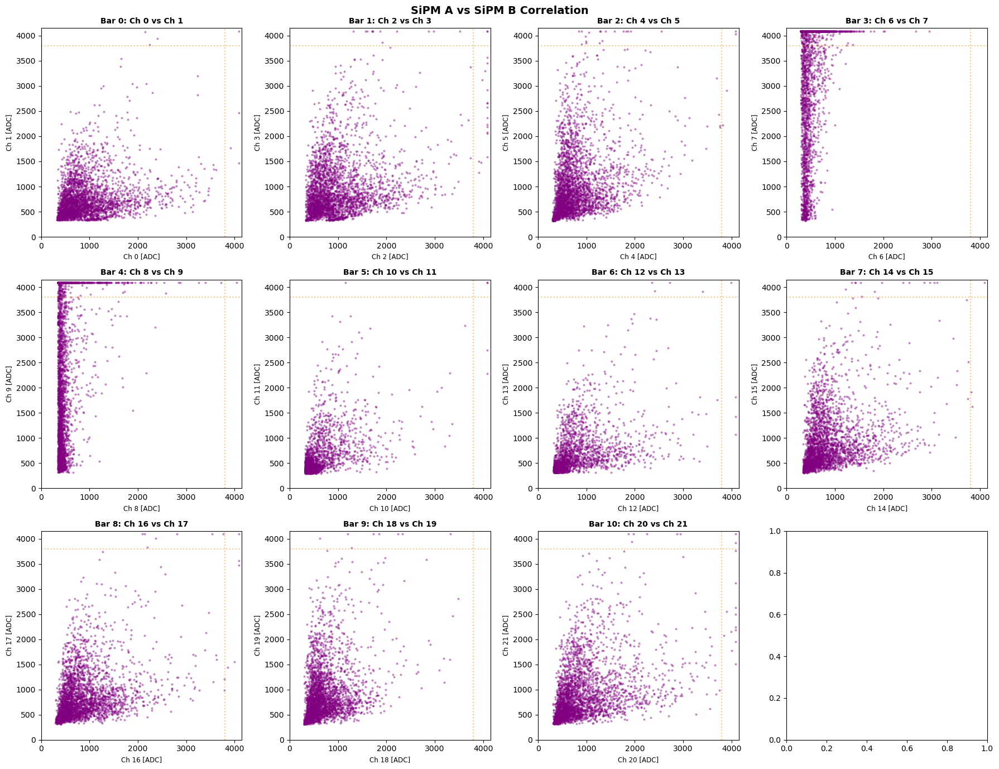

In [ ]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module1/muons_20261103-162257.h5"

BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    # 11: (22, 23),
    # 12: (24, 25),
    # 13: (26, 27),
    # 14: (28, 29),
    # 15: (30, 31)
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [22, 23, 24, 25, 26, 27, 28, 29, 30, 31]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Threshold':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas  = {}
ch_threshold = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    ch_threshold[ch] = med + 5 * sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {med + 5 * sigma:<20.2f}")

# Characteristic electronic noise per unit gain
reference_pedestal = float(np.median(list(free_pedestals.values())))
reference_sigma = float(np.median(list(free_sigmas.values())))
reference_threshold = float(np.median(list(ch_threshold.values())))
sigma_per_gain = float(np.median(norm_sigmas))
print("-" * 78)
print(f"For Gain = 10")
print(f"--> Median Pedestal: {reference_pedestal:.2f} ADC counts")
print(f"--> Median Sigma: ±{reference_sigma:.2f} ADC counts")
print (f"--> Median Threshold: {reference_threshold:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma: {sigma_per_gain:.2f} ADC counts / Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

# # Calculate the mean of free_pedestals and free_sigmas
# mean_free_pedestals = np.mean(list(free_pedestals.values()))
# mean_free_sigmas = np.mean(list(free_sigmas.values()))
lim_d = reference_pedestal - 5 * reference_sigma
lim_u = reference_threshold

# print(f"Mean of free_pedestals: {mean_free_pedestals:.2f}")
# print(f"Mean of free_sigmas: {mean_free_sigmas:.2f}")

for ch in range(n_channels):
    ch_data = charges[:, ch]
    counts, bin_edges = np.histogram(ch_data, bins=100, range=(lim_d, lim_u))
    mode_ped = bin_edges[np.argmax(counts)]
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Threshold A':<9} | {'Threshold B':<9} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'thres_a': thresholds[ch_a], 'thres_b': thresholds[ch_b],
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {thresholds[ch_a]:<2.2f}  | {thresholds[ch_b]:<2.2f} |{sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, N_bars)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars:        {n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars:           {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================
free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

max_x = np.max(list(ch_threshold.values()))
for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    thresh = ch_threshold[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=100, range=(0, max_x), color='mediumseagreen', alpha=0.75, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f} ADC)')
    ax.axvline(thresh, color='crimson', linestyle=':', label=f'+5σ Threshold ({med + 5*sig:.1f} ADC)')

    ax.set_xlim(0, max_x*1.05)
    # ax.set_yscale('log')
    
    ax.set_title(f"Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, loc='left')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Counts", fontsize=9)
    ax.legend(fontsize=7.5,  loc='upper left', facecolor='none', framealpha=0)

plt.suptitle("AND Config | DAC = 300 ", fontsize=20, y=1.0)
plt.tight_layout()

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOT 2: ACTIVE BARS
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0)
    
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if idx % n_cols == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
# print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
# print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")

-----

# Trial 00

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261105-163325.h5
Loaded 30,280 events over 146.35 seconds.
Total DAQ Trigger Rate: 206.9 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 222.00           | 10.38            | 273.89              
Ch 1       | 10     | 230.00           | 11.86            | 289.30              
Ch 2       | 10     | 241.00           | 10.38            | 292.89              
Ch 3       | 10     | 224.00           | 11.86            | 283.30              
Ch 4       | 10     | 229.00           | 11.86            | 288.30              
Ch 5       | 10     | 238.00           | 13.34            | 304.72              
Ch 28      | 10     | 244.00           | 11.86            | 303.30              
Ch 29      | 10     | 245.00           | 10.38            | 296.

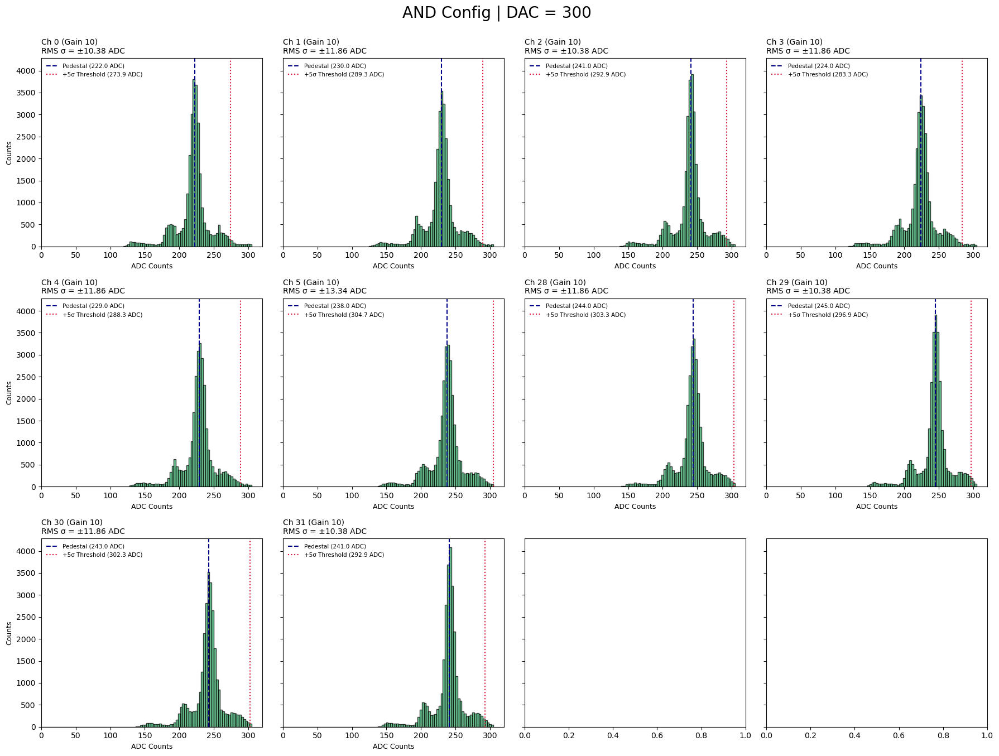

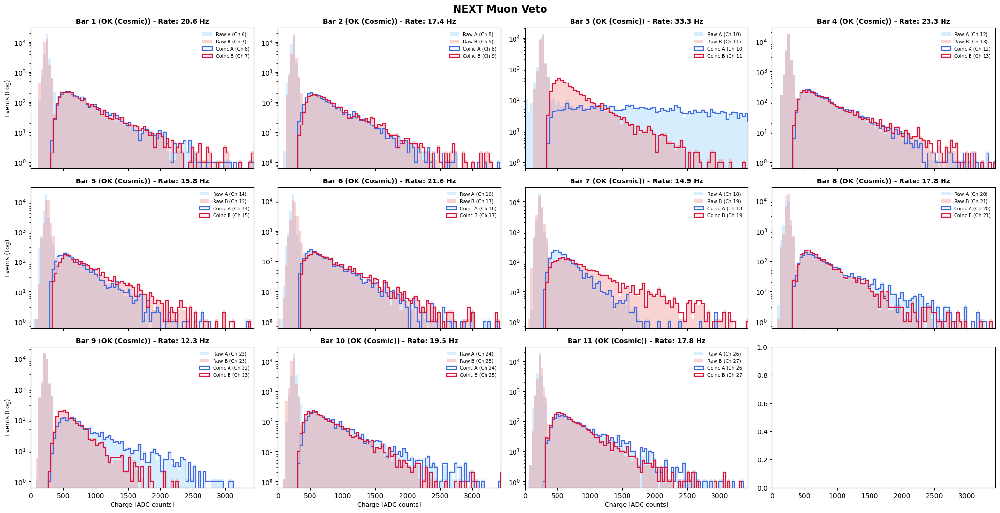

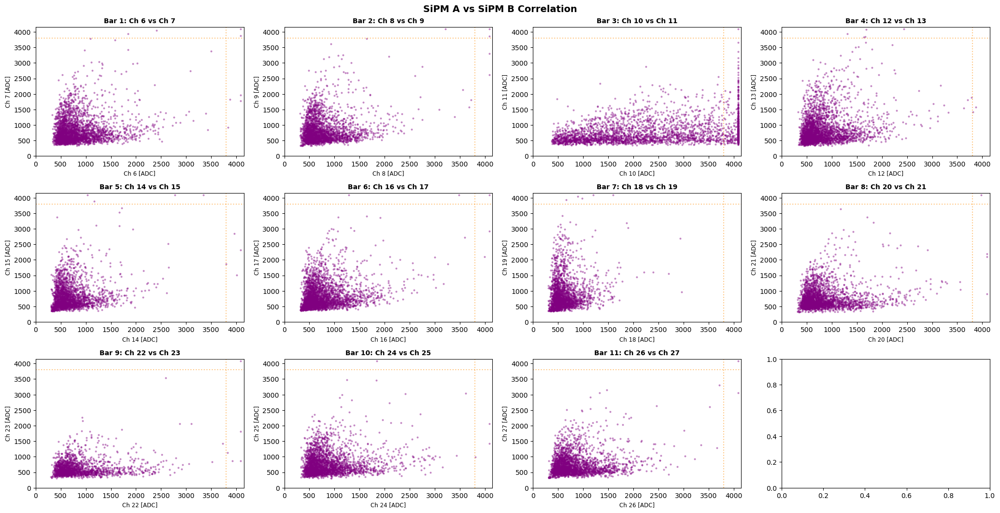

In [2]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261105-163325.h5"

BAR_MAP = {
    # 0:  (0, 1),
    # 1:  (2, 3),
    # 2:  (4, 5),
    1:  (6, 7),
    2:  (8, 9),
    3:  (10, 11),
    4:  (12, 13),
    5:  (14, 15),
    6:  (16, 17),
    7:  (18, 19),
    8: (20, 21),
    9: (22, 23),
    10: (24, 25),
    11: (26, 27),
    # 14: (28, 29),
    # 15: (30, 31)
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [0, 1, 2, 3, 4, 5, 28, 29, 30, 31]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Threshold':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas  = {}
ch_threshold = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    ch_threshold[ch] = med + 5 * sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {med + 5 * sigma:<20.2f}")

# Characteristic electronic noise per unit gain
reference_pedestal = float(np.median(list(free_pedestals.values())))
reference_sigma = float(np.median(list(free_sigmas.values())))
reference_threshold = float(np.median(list(ch_threshold.values())))
sigma_per_gain = float(np.median(norm_sigmas))
print("-" * 78)
print(f"For Gain = 10")
print(f"--> Median Pedestal: {reference_pedestal:.2f} ADC counts")
print(f"--> Median Sigma: ±{reference_sigma:.2f} ADC counts")
print (f"--> Median Threshold: {reference_threshold:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma: {sigma_per_gain:.2f} ADC counts / Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

# # Calculate the mean of free_pedestals and free_sigmas
# mean_free_pedestals = np.mean(list(free_pedestals.values()))
# mean_free_sigmas = np.mean(list(free_sigmas.values()))
lim_d = reference_pedestal - 5 * reference_sigma
lim_u = reference_threshold

# print(f"Mean of free_pedestals: {mean_free_pedestals:.2f}")
# print(f"Mean of free_sigmas: {mean_free_sigmas:.2f}")

for ch in range(n_channels):
    ch_data = charges[:, ch]
    counts, bin_edges = np.histogram(ch_data, bins=100, range=(lim_d, lim_u))
    mode_ped = bin_edges[np.argmax(counts)]
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Threshold A':<9} | {'Threshold B':<9} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'thres_a': thresholds[ch_a], 'thres_b': thresholds[ch_b],
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {thresholds[ch_a]:<2.2f}  | {thresholds[ch_b]:<2.2f} |{sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, N_bars)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars:        {n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars:           {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================
free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

max_x = np.max(list(ch_threshold.values()))
for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    thresh = ch_threshold[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=100, range=(0, max_x), color='mediumseagreen', alpha=0.75, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f} ADC)')
    ax.axvline(thresh, color='crimson', linestyle=':', label=f'+5σ Threshold ({med + 5*sig:.1f} ADC)')

    ax.set_xlim(0, max_x*1.05)
    # ax.set_yscale('log')
    
    ax.set_title(f"Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, loc='left')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Counts", fontsize=9)
    ax.legend(fontsize=7.5,  loc='upper left', facecolor='none', framealpha=0)

plt.suptitle("AND Config | DAC = 300 ", fontsize=20, y=1.0)
plt.tight_layout()

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOT 2: ACTIVE BARS
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0)
    
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if idx % n_cols == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
# print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
# print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")

# Final

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261109-134931.h5
Loaded 26,962 events over 126.30 seconds.
Total DAQ Trigger Rate: 213.5 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 218.00           | 10.38            | 269.89              
Ch 1       | 10     | 226.00           | 11.86            | 285.30              
Ch 2       | 10     | 237.00           | 10.38            | 288.89              
Ch 3       | 10     | 221.00           | 11.86            | 280.30              
Ch 4       | 10     | 227.00           | 16.31            | 308.54              
Ch 5       | 10     | 236.00           | 14.83            | 310.13              
Ch 28      | 10     | 241.00           | 11.86            | 300.30              
Ch 29      | 10     | 242.00           | 10.38            | 293.

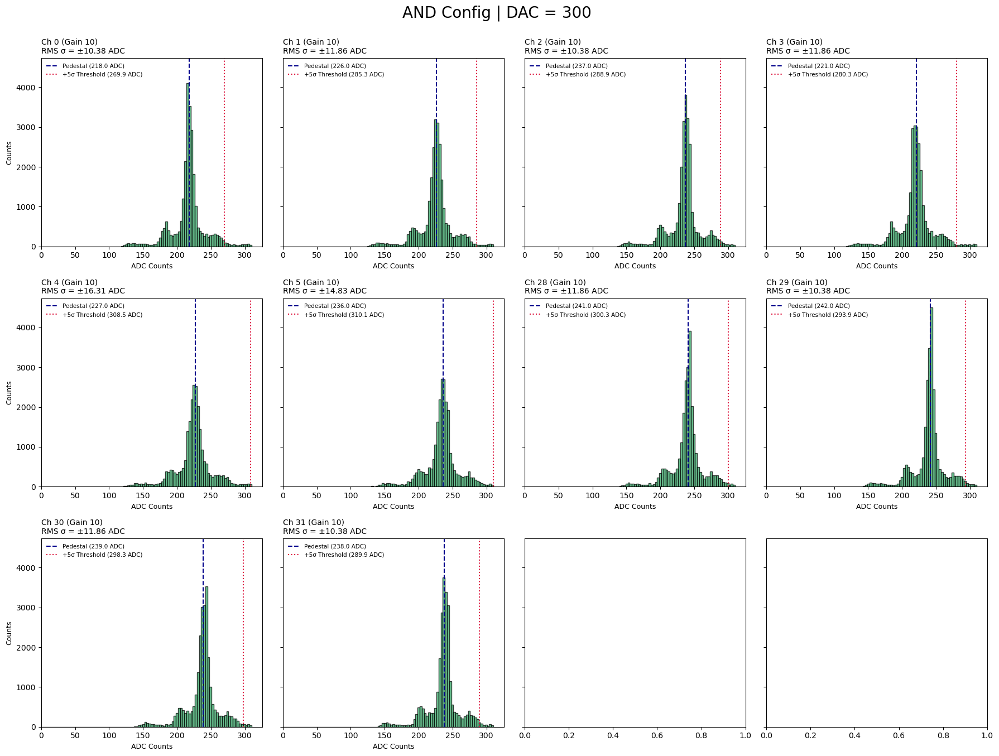

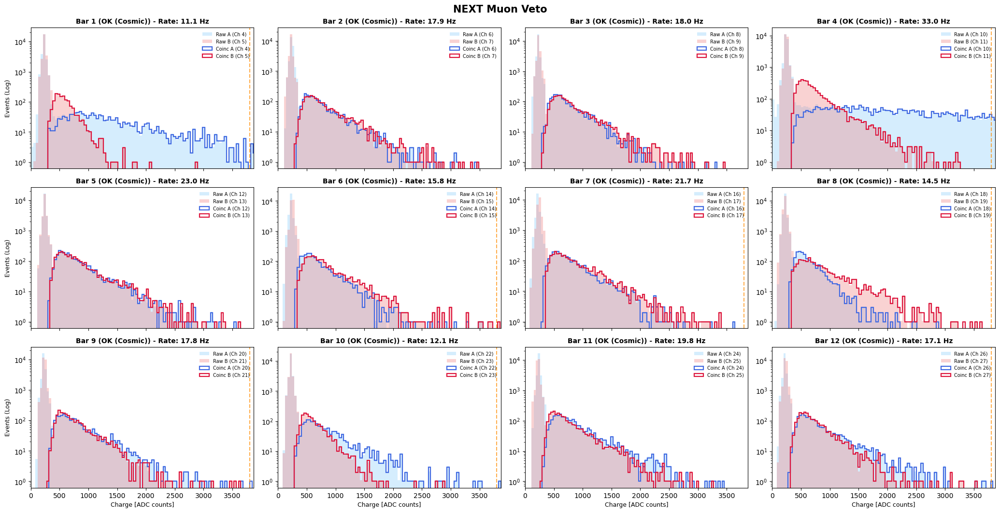

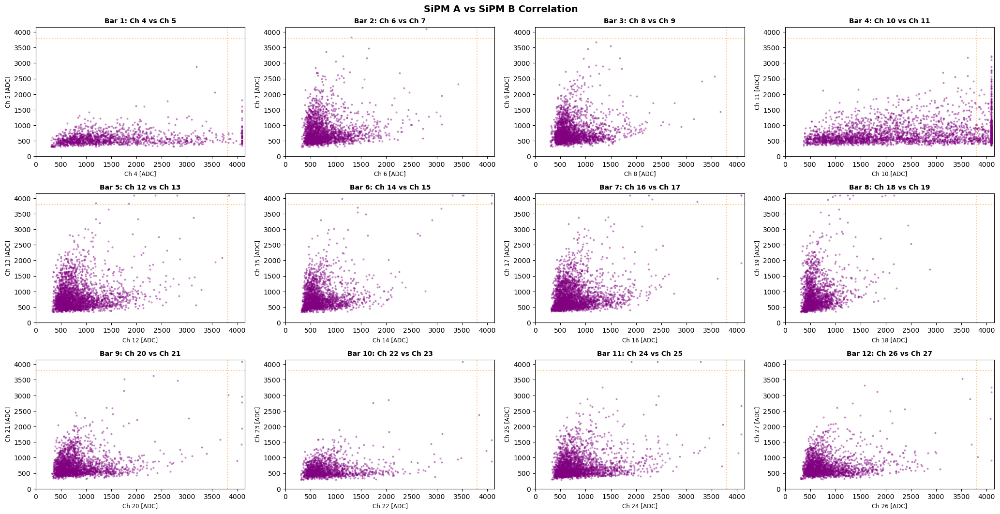

In [3]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/module2/muons_20261109-134931.h5"

BAR_MAP = {
    # 0:  (0, 1),
    # 1:  (2, 3),
    1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    # 14: (28, 29),
    # 15: (30, 31)
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [0, 1, 2, 3, 4, 5, 28, 29, 30, 31]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH}")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff  = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE CHARACTERIZATION
# ==============================================================================
print("=" * 78)
print("ELECTRONIC NOISE FROM UNCONNECTED CHANNELS")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Threshold':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas  = {}
ch_threshold = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch]    = sigma
    ch_threshold[ch] = med + 5 * sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {med + 5 * sigma:<20.2f}")

# Characteristic electronic noise per unit gain
reference_pedestal = float(np.median(list(free_pedestals.values())))
reference_sigma = float(np.median(list(free_sigmas.values())))
reference_threshold = float(np.median(list(ch_threshold.values())))
sigma_per_gain = float(np.median(norm_sigmas))
print("-" * 78)
print(f"For Gain = 10")
print(f"--> Median Pedestal: {reference_pedestal:.2f} ADC counts")
print(f"--> Median Sigma: ±{reference_sigma:.2f} ADC counts")
print (f"--> Median Threshold: {reference_threshold:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma: {sigma_per_gain:.2f} ADC counts / Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

# # Calculate the mean of free_pedestals and free_sigmas
# mean_free_pedestals = np.mean(list(free_pedestals.values()))
# mean_free_sigmas = np.mean(list(free_sigmas.values()))
lim_d = reference_pedestal - 5 * reference_sigma
lim_u = reference_threshold

# print(f"Mean of free_pedestals: {mean_free_pedestals:.2f}")
# print(f"Mean of free_sigmas: {mean_free_sigmas:.2f}")

for ch in range(n_channels):
    ch_data = charges[:, ch]
    counts, bin_edges = np.histogram(ch_data, bins=100, range=(lim_d, lim_u))
    mode_ped = bin_edges[np.argmax(counts)]
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Threshold A':<9} | {'Threshold B':<9} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'thres_a': thresholds[ch_a], 'thres_b': thresholds[ch_b],
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {thresholds[ch_a]:<2.2f}  | {thresholds[ch_b]:<2.2f} |{sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, N_bars)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars:        {n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars:           {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS
# ==============================================================================
free_rows = (len(FREE_CHANNELS) + 3) // 4  # Calculate rows dynamically based on FREE_CHANNELS
fig_f, axes_f = plt.subplots(free_rows, 4, figsize=(18, 4.5 * free_rows), sharey=True)
axes_f = axes_f.flatten()

max_x = np.max(list(ch_threshold.values()))
for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes_f[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    thresh = ch_threshold[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=100, range=(0, max_x), color='mediumseagreen', alpha=0.75, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f} ADC)')
    ax.axvline(thresh, color='crimson', linestyle=':', label=f'+5σ Threshold ({med + 5*sig:.1f} ADC)')

    ax.set_xlim(0, max_x*1.05)
    # ax.set_yscale('log')
    
    ax.set_title(f"Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, loc='left')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Counts", fontsize=9)
    ax.legend(fontsize=7.5,  loc='upper left', facecolor='none', framealpha=0)

plt.suptitle("AND Config | DAC = 300 ", fontsize=20, y=1.0)
plt.tight_layout()

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOT 2: ACTIVE BARS
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0)
    
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if idx % n_cols == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
# print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
# print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")

# Tuning Process

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-155924.h5
Loaded 11,703 events over 57.10 seconds.
Total DAQ Trigger Rate: 205.0 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 215.00           | 20.76            | 318.78              
Ch 1       | 10     | 223.00           | 13.34            | 289.72              
Ch 2       | 10     | 235.00           | 22.24            | 346.19              
Ch 3       | 10     | 218.00           | 13.34            | 284.72              
Ch 28      | 10     | 239.00           | 13.34            | 305.72              
Ch 29      | 10     | 237.00           | 20.76            | 340.78              
Ch 30      | 10     | 237.00           | 11.86            | 296.30              
Ch 31      | 10     | 233.00           | 20.76            | 336

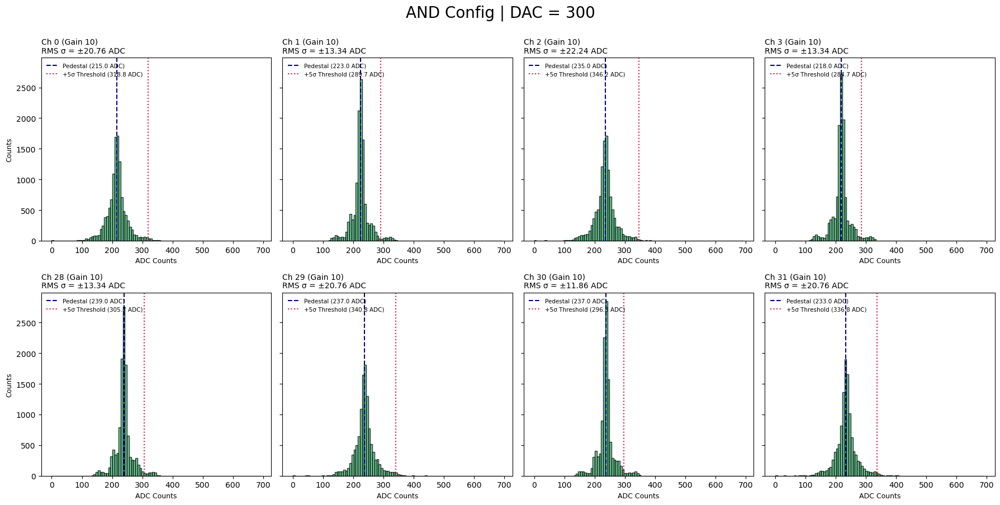

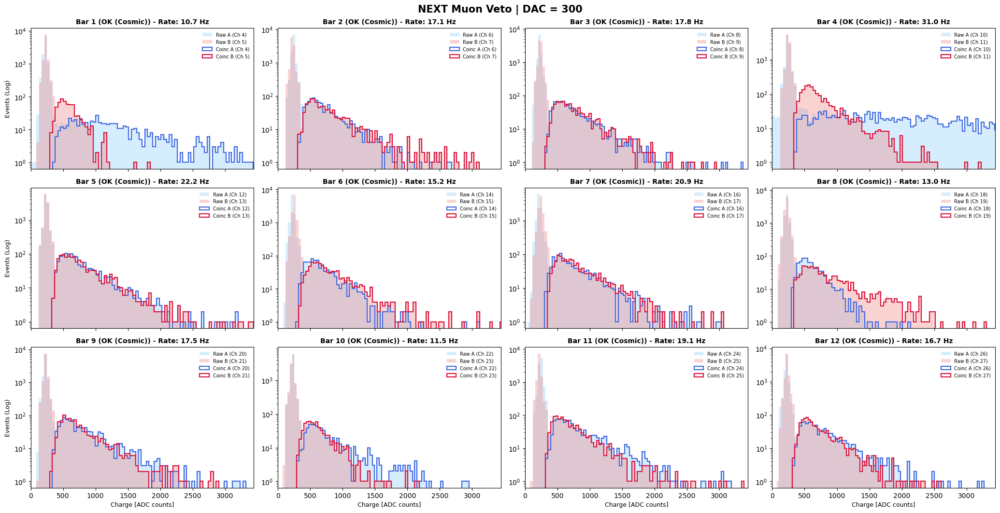

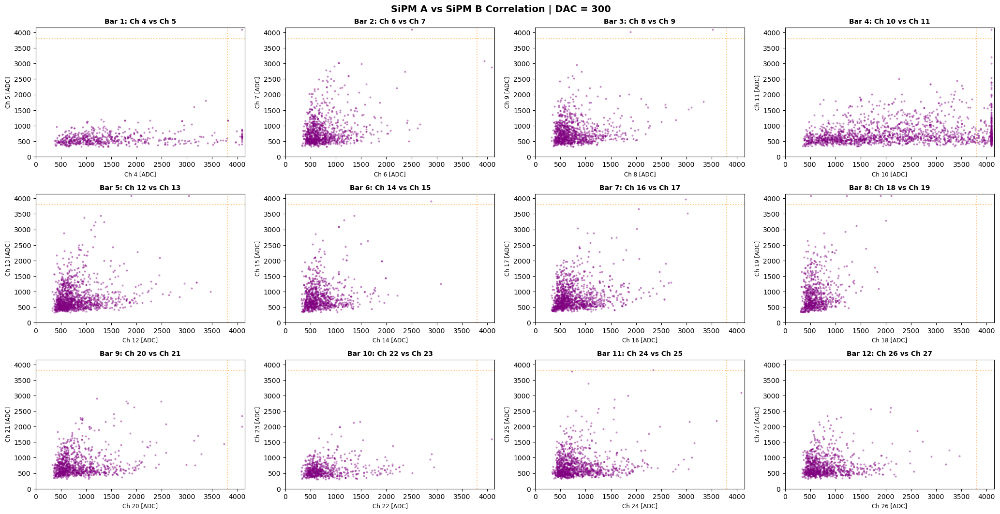


Done! All diagnostic plots and rate reconciliations generated.


In [4]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-155924.h5"

BAR_MAP = {
    # X:  (0, 1),
    # X:  (2, 3),
    1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    # X: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 2, 3, 28, 29, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    4: {"gain": 7, "bias": 120},
    10: {"gain": 5, "bias": 120},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-160405.h5
Loaded 12,333 events over 60.55 seconds.
Total DAQ Trigger Rate: 203.7 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 212.00           | 20.76            | 315.78              
Ch 1       | 10     | 220.00           | 13.34            | 286.72              
Ch 2       | 10     | 232.00           | 20.76            | 335.78              
Ch 3       | 10     | 215.00           | 11.86            | 274.30              
Ch 28      | 10     | 235.00           | 13.34            | 301.72              
Ch 29      | 10     | 234.00           | 19.27            | 330.37              
Ch 30      | 10     | 234.00           | 11.86            | 293.30              
Ch 31      | 10     | 230.00           | 17.79            | 318

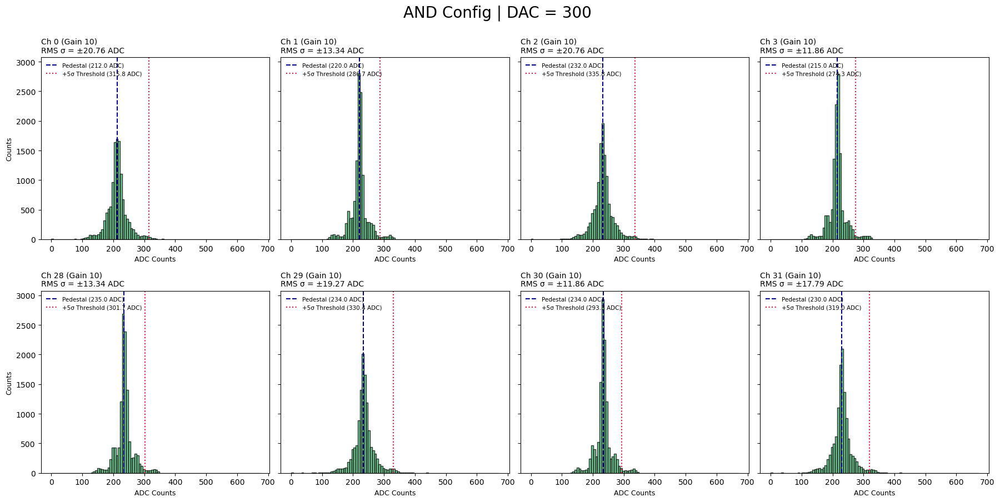

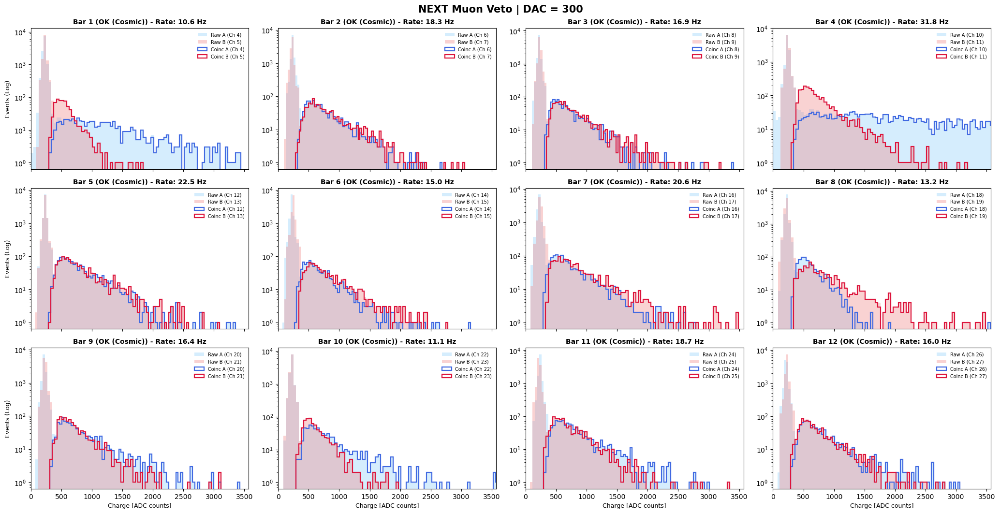

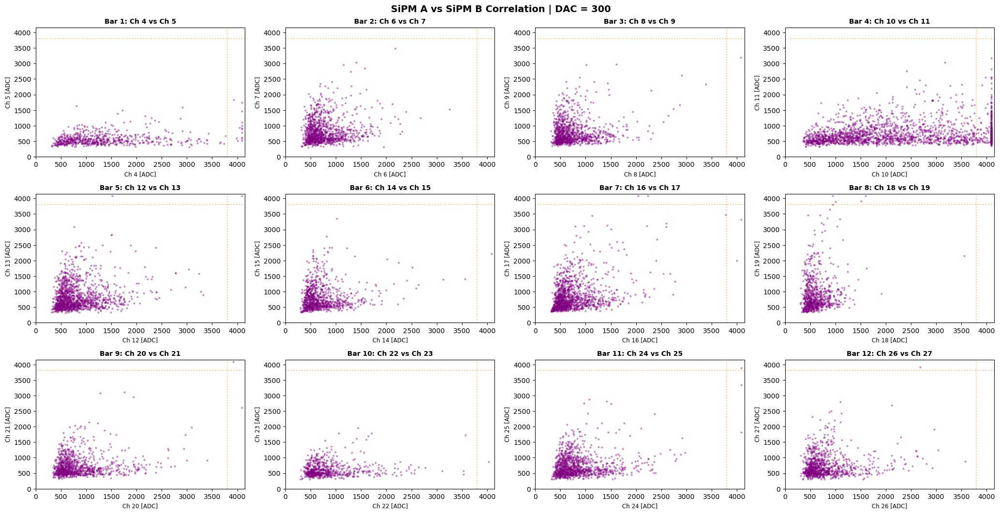


Done! All diagnostic plots and rate reconciliations generated.


In [5]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-160405.h5"

BAR_MAP = {
    # X:  (0, 1),
    # X:  (2, 3),
    1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    # X: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 2, 3, 28, 29, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    4: {"gain": 5, "bias": 140},
    10: {"gain": 2, "bias": 140},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-160724.h5
Loaded 11,247 events over 56.15 seconds.
Total DAQ Trigger Rate: 200.3 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 211.00           | 19.27            | 307.37              
Ch 1       | 10     | 220.00           | 13.34            | 286.72              
Ch 2       | 10     | 231.00           | 20.76            | 334.78              
Ch 3       | 10     | 214.00           | 13.34            | 280.72              
Ch 28      | 10     | 234.00           | 11.86            | 293.30              
Ch 29      | 10     | 233.00           | 19.27            | 329.37              
Ch 30      | 10     | 233.00           | 13.34            | 299.72              
Ch 31      | 10     | 229.00           | 17.79            | 317

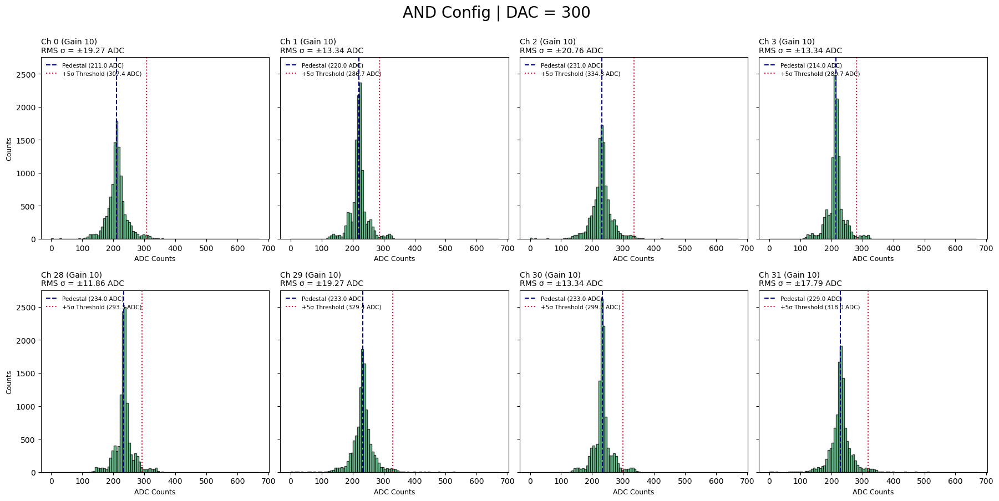

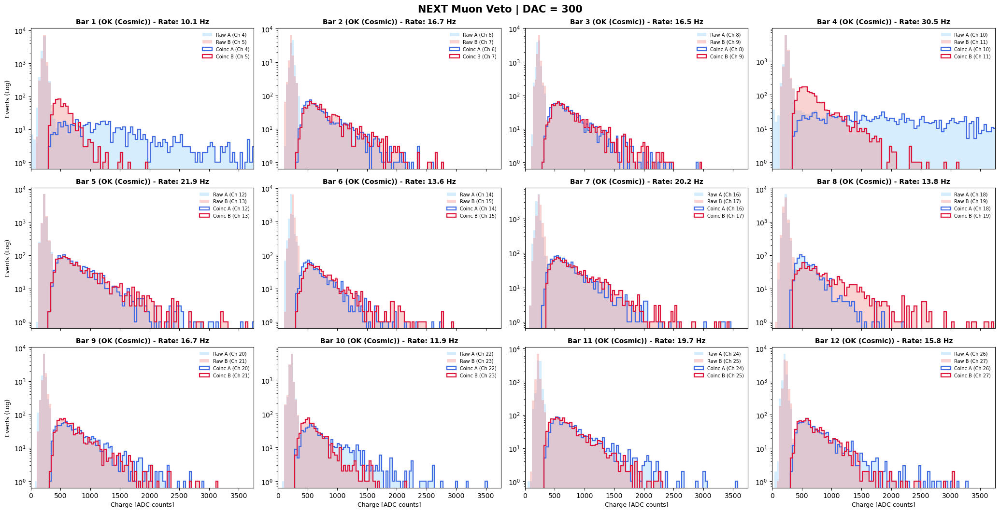

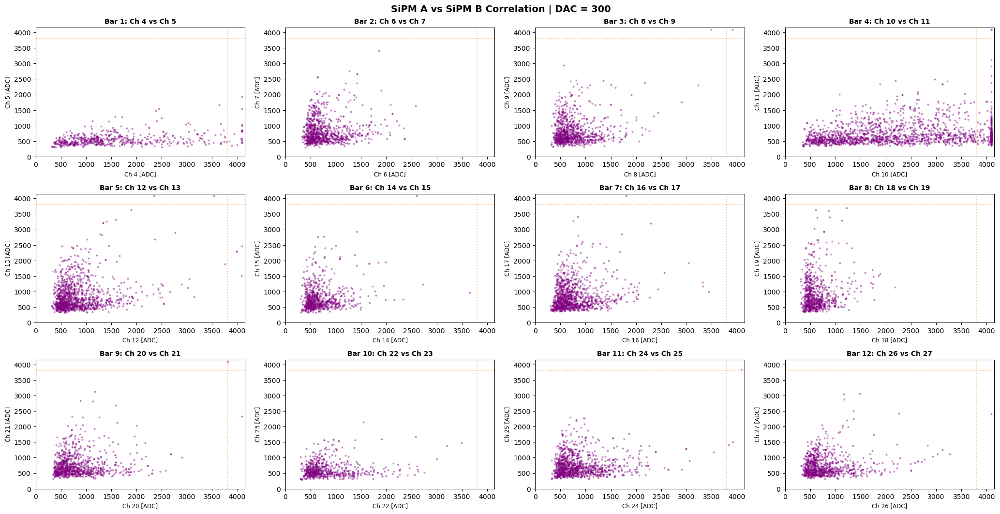


Done! All diagnostic plots and rate reconciliations generated.


In [6]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-160724.h5"

BAR_MAP = {
    # X:  (0, 1),
    # X:  (2, 3),
    1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    # X: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 2, 3, 28, 29, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    4: {"gain": 5, "bias": 80},
    10: {"gain": 2, "bias": 200},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-161000.h5
Loaded 10,933 events over 52.95 seconds.
Total DAQ Trigger Rate: 206.5 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 211.00           | 19.27            | 307.37              
Ch 1       | 10     | 219.00           | 13.34            | 285.72              
Ch 2       | 10     | 230.00           | 20.76            | 333.78              
Ch 3       | 10     | 214.00           | 13.34            | 280.72              
Ch 28      | 10     | 234.00           | 13.34            | 300.72              
Ch 29      | 10     | 233.00           | 19.27            | 329.37              
Ch 30      | 10     | 233.00           | 11.86            | 292.30              
Ch 31      | 10     | 229.00           | 19.27            | 325

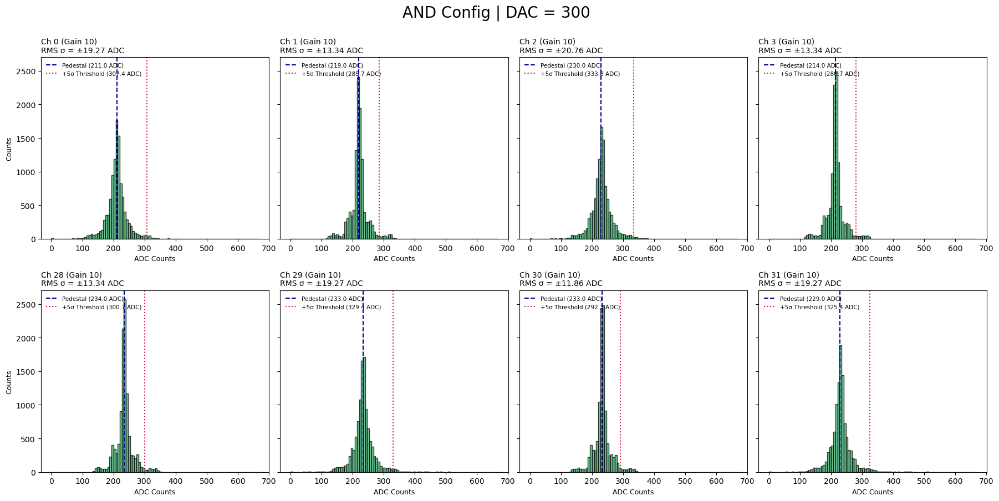

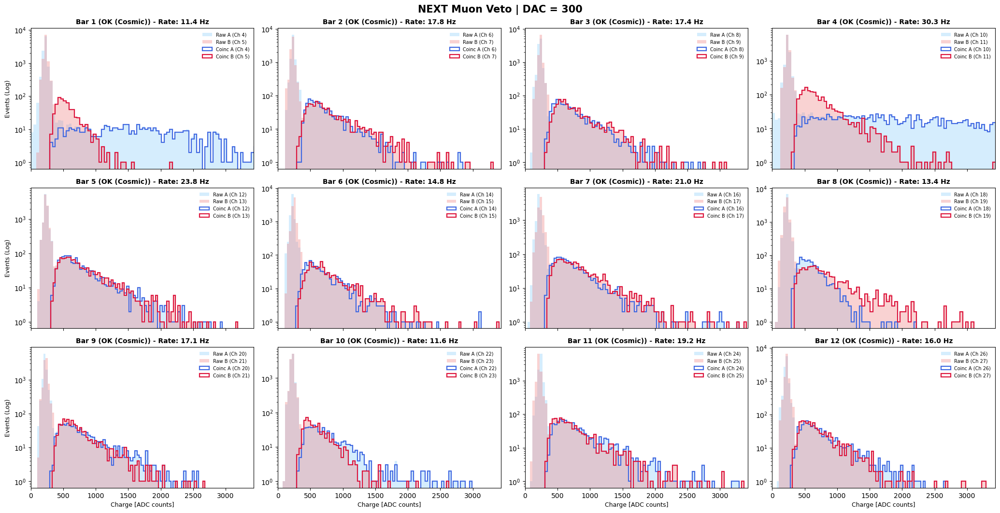

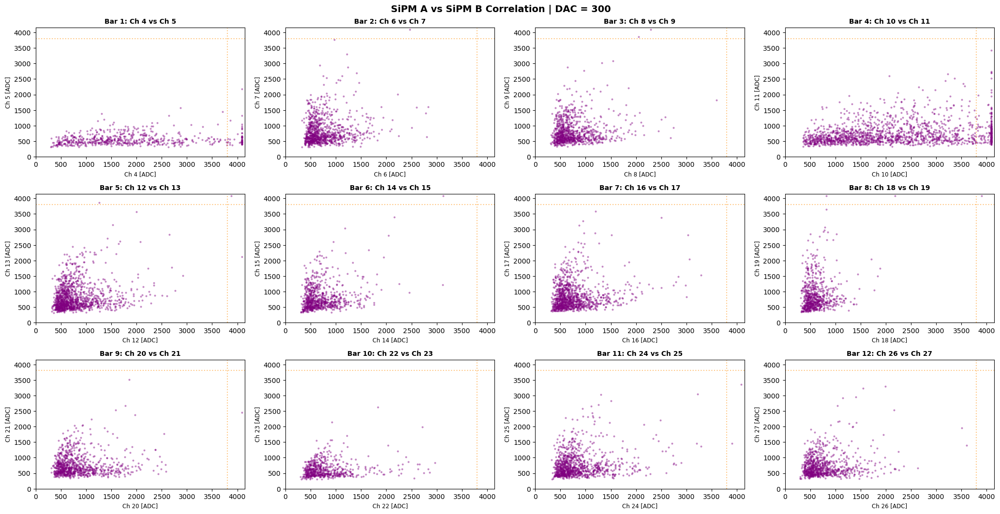


Done! All diagnostic plots and rate reconciliations generated.


In [7]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-161000.h5"

BAR_MAP = {
    # X:  (0, 1),
    # X:  (2, 3),
    1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    # X: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 2, 3, 28, 29, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    4: {"gain": 0, "bias": 0},
    10: {"gain": 0, "bias": 140},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-162303.h5
Loaded 10,433 events over 54.55 seconds.
Total DAQ Trigger Rate: 191.3 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 217.00           | 19.27            | 313.37              
Ch 1       | 10     | 225.00           | 13.34            | 291.72              
Ch 4       | 10     | 225.00           | 13.34            | 291.72              
Ch 5       | 10     | 234.00           | 13.34            | 300.72              
Ch 10      | 10     | 249.00           | 11.86            | 308.30              
Ch 11      | 10     | 249.00           | 11.86            | 308.30              
Ch 30      | 10     | 239.00           | 11.86            | 298.30              
Ch 31      | 10     | 235.00           | 17.79            | 323

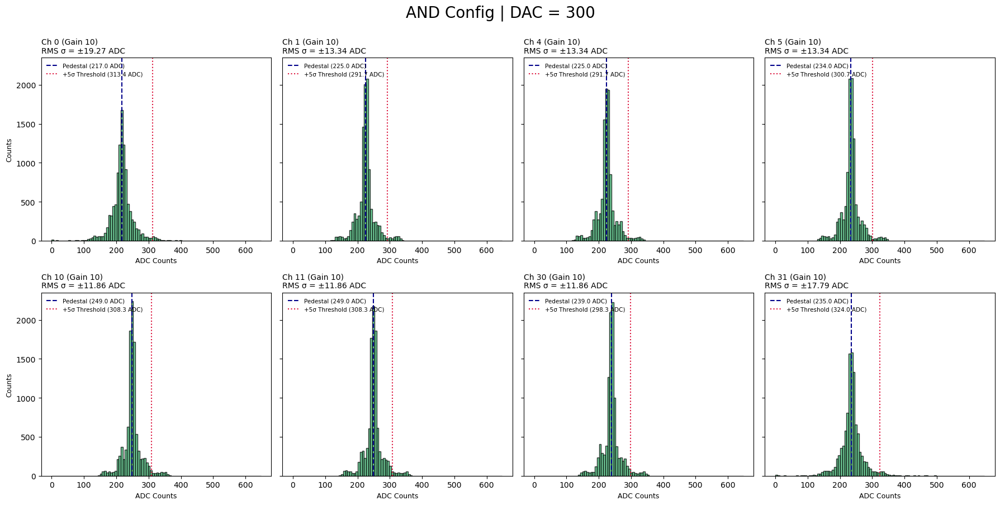

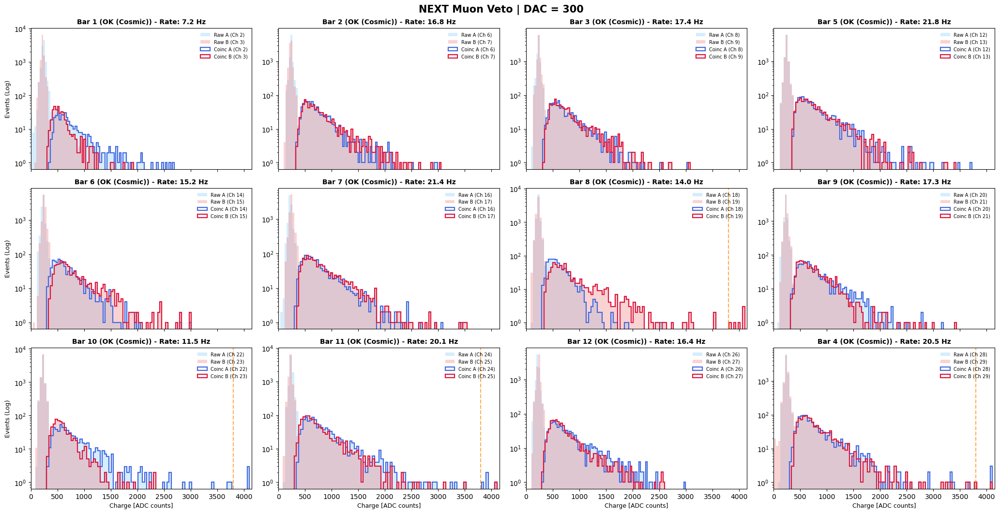

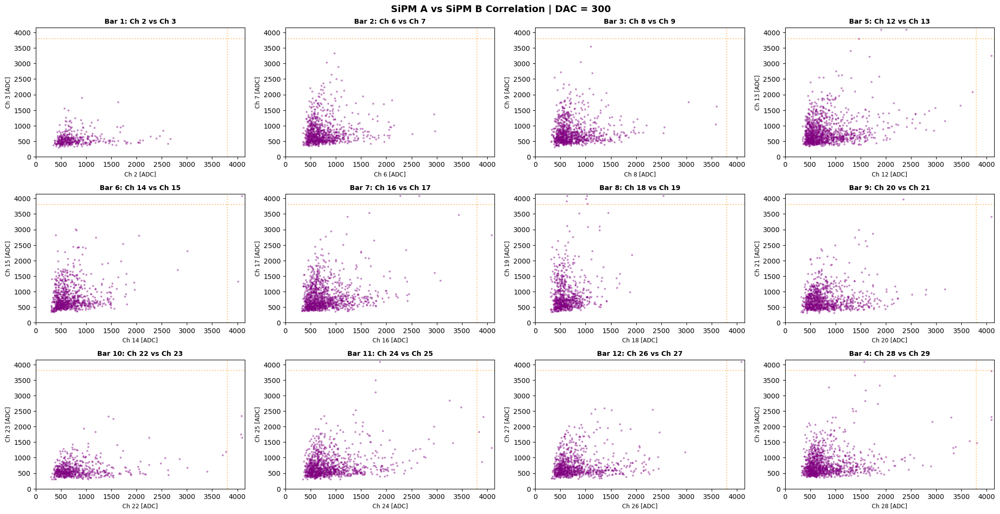


Done! All diagnostic plots and rate reconciliations generated.


In [8]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-162303.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # 1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # 4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 4, 5, 10, 11, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
# CHANNEL_CONFIG.update({
#     4: {"gain": 10, "bias": 140},
#     10: {"gain": 10, "bias": 140},
# })
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-162853.h5
Loaded 10,630 events over 49.25 seconds.
Total DAQ Trigger Rate: 215.8 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 212.00           | 19.27            | 308.37              
Ch 1       | 10     | 221.00           | 11.86            | 280.30              
Ch 4       | 10     | 221.00           | 13.34            | 287.72              
Ch 5       | 10     | 230.00           | 13.34            | 296.72              
Ch 10      | 10     | 244.00           | 11.86            | 303.30              
Ch 11      | 10     | 245.00           | 11.86            | 304.30              
Ch 30      | 10     | 235.00           | 11.86            | 294.30              
Ch 31      | 10     | 231.00           | 17.79            | 319

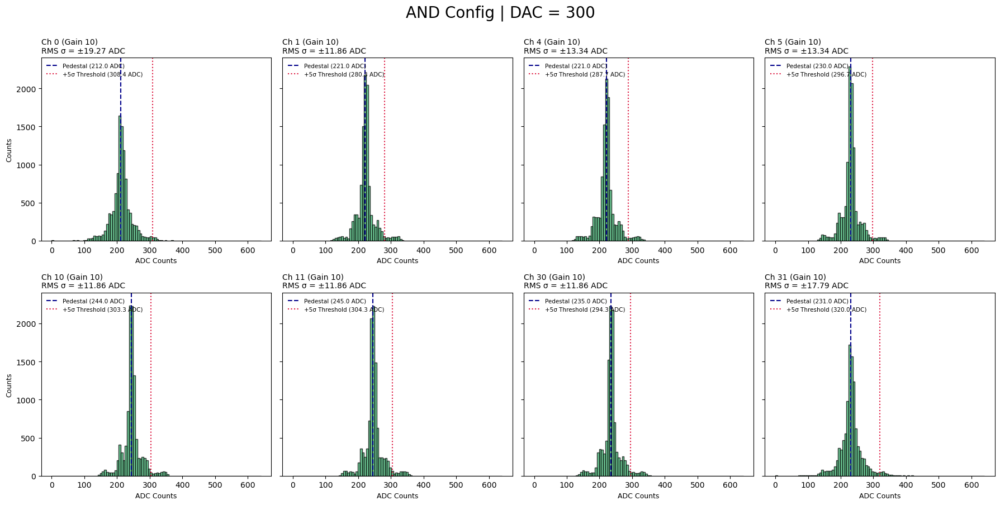

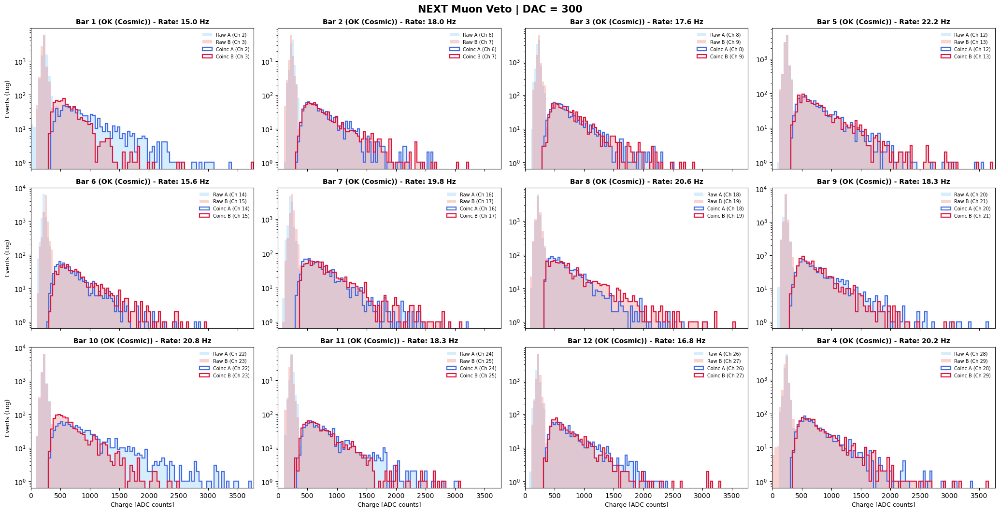

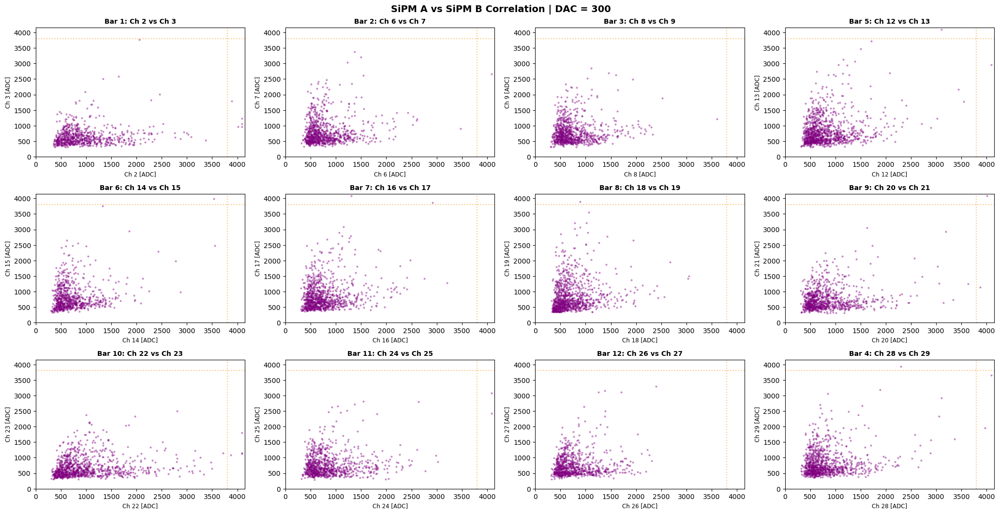


Done! All diagnostic plots and rate reconciliations generated.


In [11]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-162853.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # 1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # 4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 4, 5, 10, 11, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    2: {"gain": 10, "bias": 170},
    3: {"gain": 10, "bias": 170},
    18: {"gain": 10, "bias": 170},
    22: {"gain": 10, "bias": 170},
    23: {"gain": 10, "bias": 170},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-163101.h5
Loaded 10,714 events over 47.85 seconds.
Total DAQ Trigger Rate: 223.9 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 211.00           | 19.27            | 307.37              
Ch 1       | 10     | 220.00           | 13.34            | 286.72              
Ch 4       | 10     | 220.00           | 13.34            | 286.72              
Ch 5       | 10     | 229.00           | 13.34            | 295.72              
Ch 10      | 10     | 243.00           | 11.86            | 302.30              
Ch 11      | 10     | 244.00           | 11.86            | 303.30              
Ch 30      | 10     | 234.00           | 11.86            | 293.30              
Ch 31      | 10     | 230.00           | 19.27            | 326

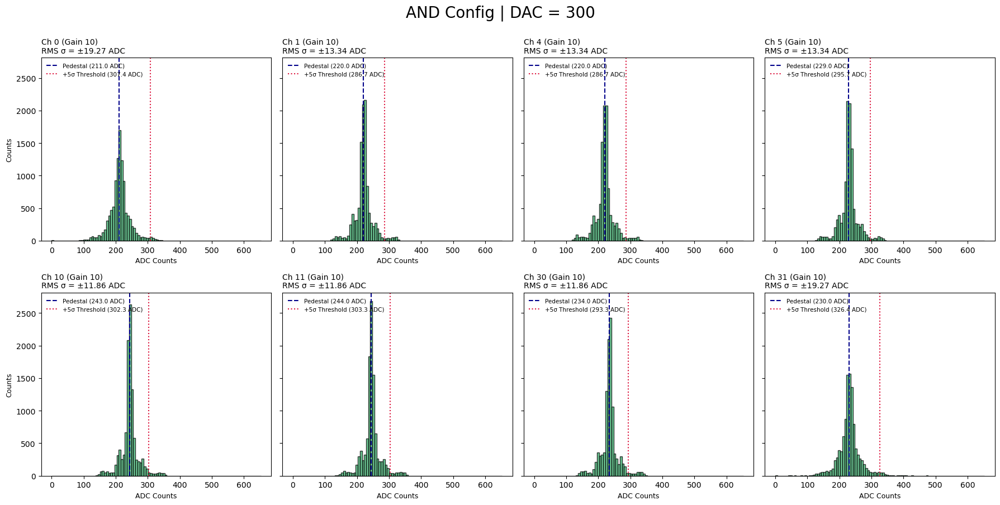

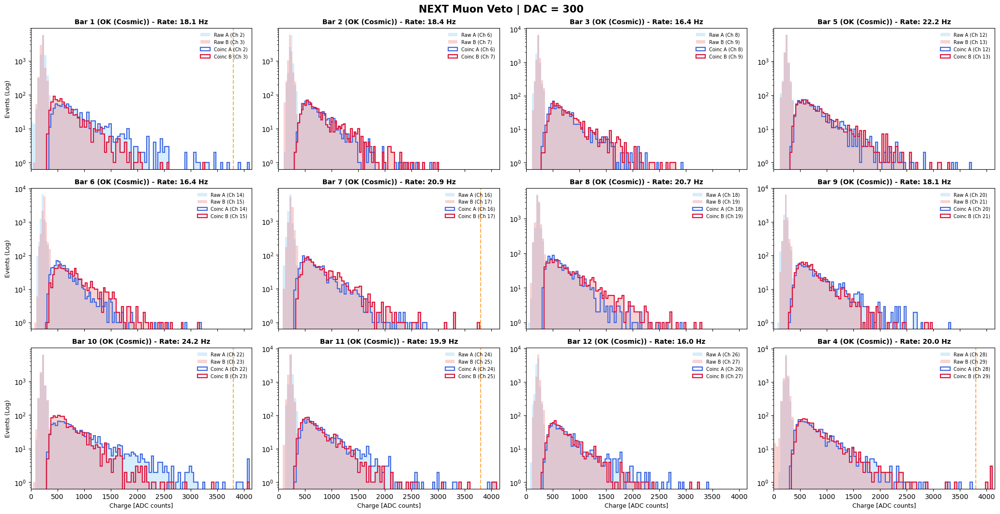

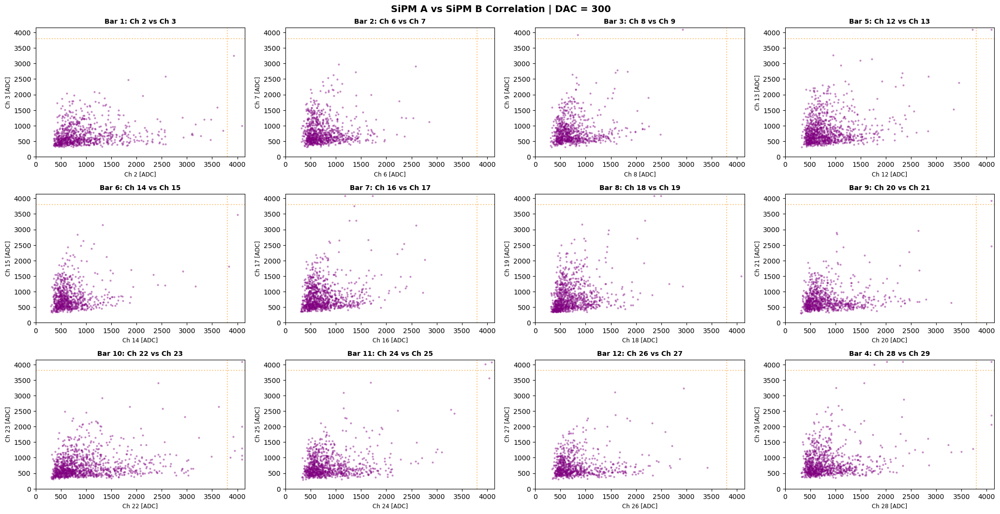


Done! All diagnostic plots and rate reconciliations generated.


In [12]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261110-163101.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # 1:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # 4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 4, 5, 10, 11, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    2: {"gain": 10, "bias": 170},
    3: {"gain": 10, "bias": 185},
    18: {"gain": 10, "bias": 170},
    22: {"gain": 10, "bias": 170},
    23: {"gain": 10, "bias": 180},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

# CARD 67 (6)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261112-155329.h5
Loaded 10,453 events over 26.05 seconds.
Total DAQ Trigger Rate: 401.3 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 0       | 10     | 126.00           | 17.79            | 214.96              
Ch 1       | 10     | 132.00           | 11.86            | 191.30              
Ch 4       | 10     | 123.00           | 11.86            | 182.30              
Ch 5       | 10     | 120.00           | 11.86            | 179.30              
Ch 10      | 10     | 108.00           | 11.86            | 167.30              
Ch 11      | 10     | 128.00           | 11.86            | 187.30              
Ch 30      | 10     | 123.00           | 11.86            | 182.30              
Ch 31      | 10     | 116.00           | 19.27            | 212

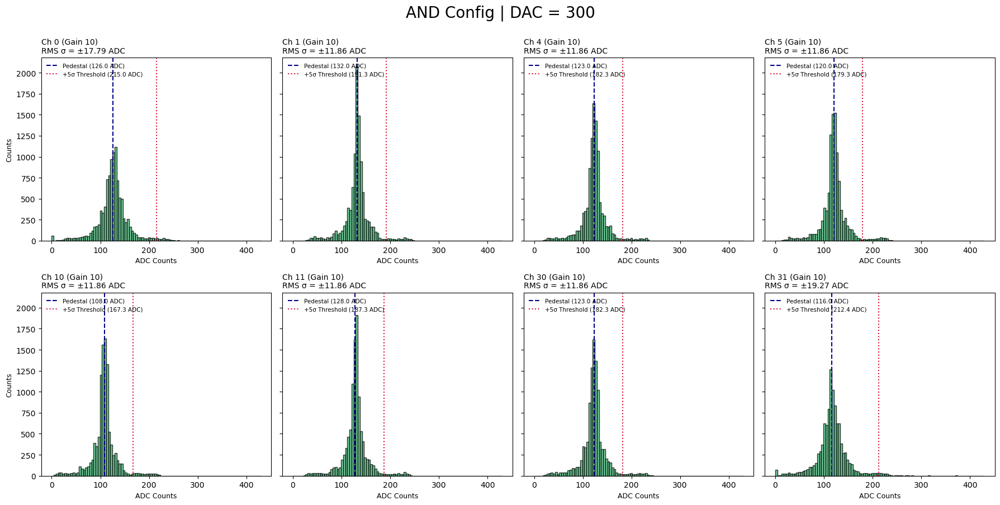

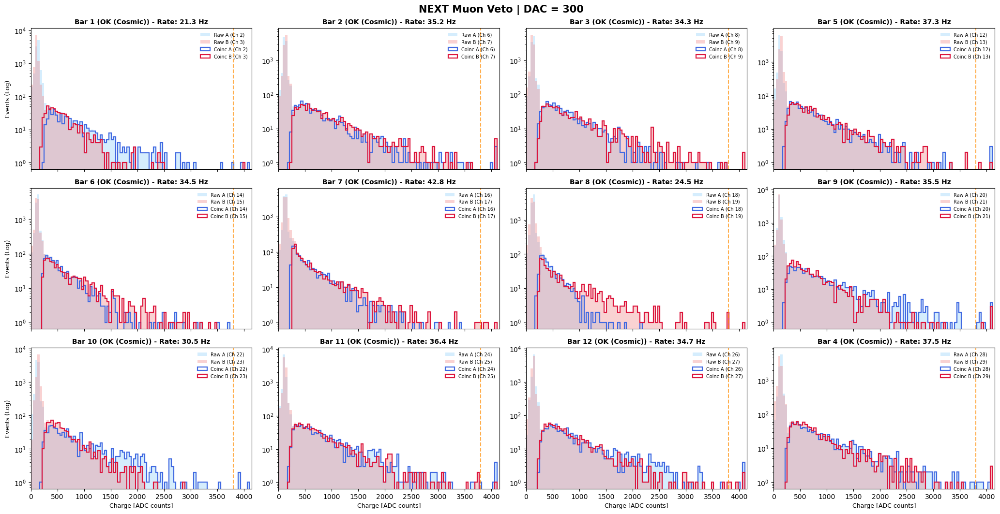

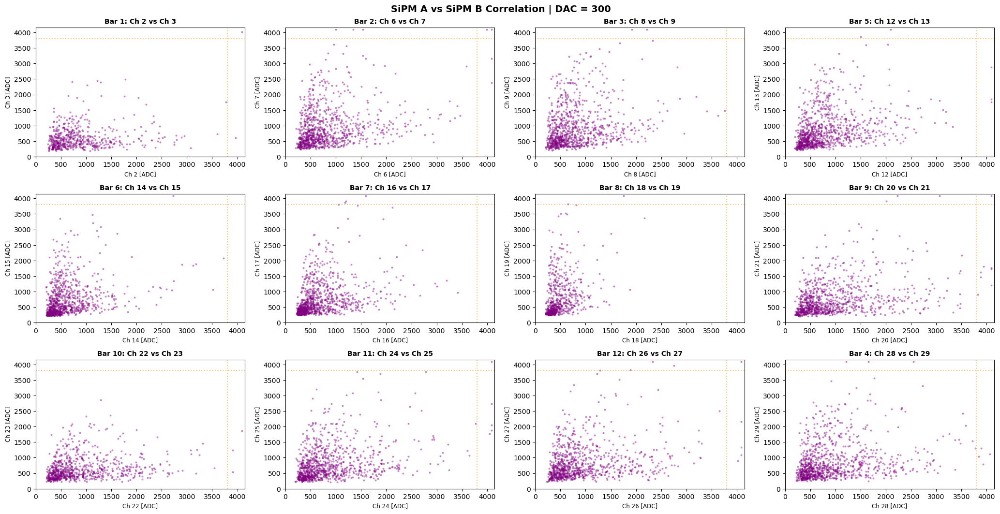


Done! All diagnostic plots and rate reconciliations generated.


In [4]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261112-155329.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # X:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # 4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [0, 1, 4, 5, 10, 11, 30, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    12: {"gain": 10, "bias": 130},
    13: {"gain": 10, "bias": 130},
    14: {"gain": 10, "bias": 130},
    15: {"gain": 10, "bias": 130},
    16: {"gain": 10, "bias": 120},
    17: {"gain": 10, "bias": 120},
    18: {"gain": 10, "bias": 120},
    19: {"gain": 10, "bias": 120},
#     22: {"gain": 11, "bias": 140},
#     22: {"gain": 11, "bias": 140},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261112-161522.h5
Loaded 11,889 events over 31.30 seconds.
Total DAQ Trigger Rate: 379.8 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold           
------------------------------------------------------------------------------
Ch 1       | 10     | 130.00           | 11.86            | 189.30              
Ch 4       | 10     | 121.00           | 11.86            | 180.30              
Ch 5       | 10     | 119.00           | 11.86            | 178.30              
Ch 11      | 10     | 127.00           | 11.86            | 186.30              
Ch 30      | 10     | 121.00           | 11.86            | 180.30              
------------------------------------------------------------------------------
For Gain = 10
--> Median Pedestal: 121.00 ADC counts
--> Median Sigma: ±11.86 ADC counts
--> Median Threshold: 180.30 ADC counts
--> Normalized El

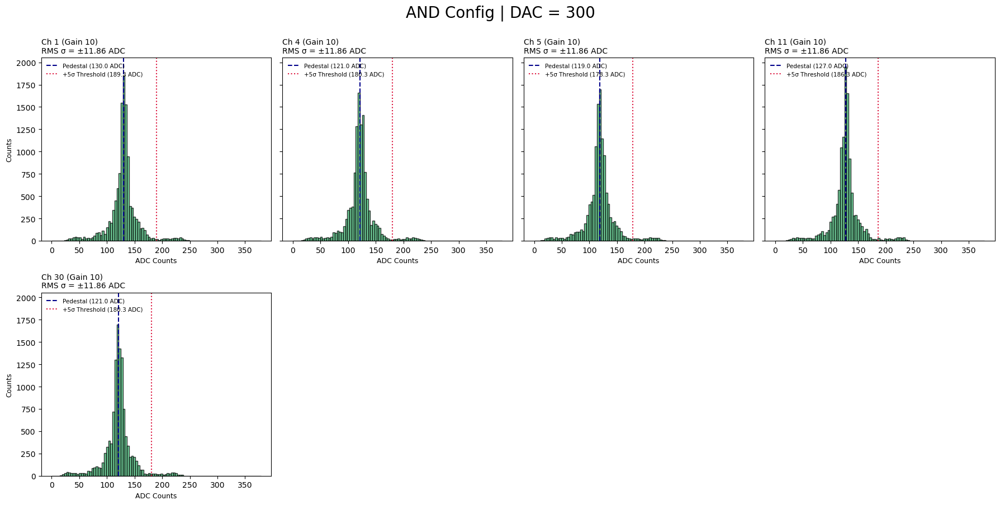

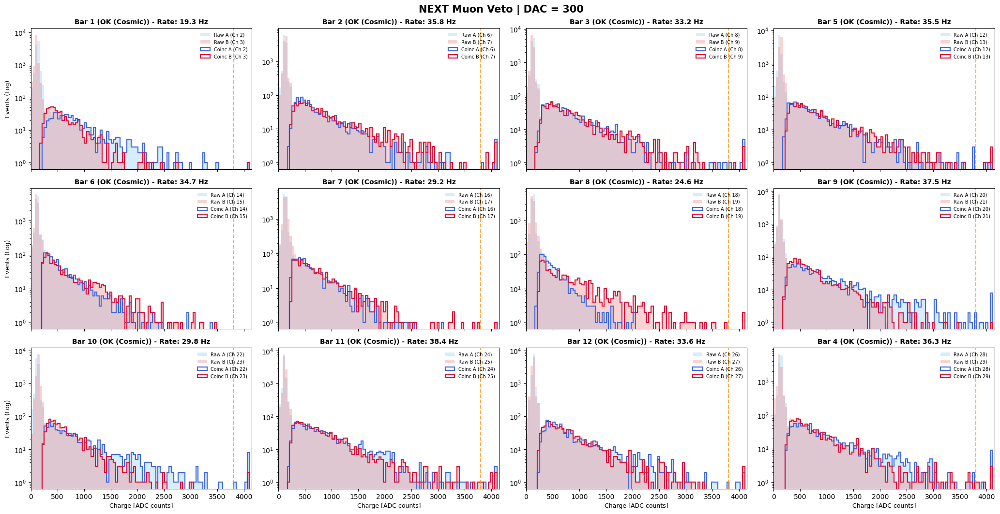

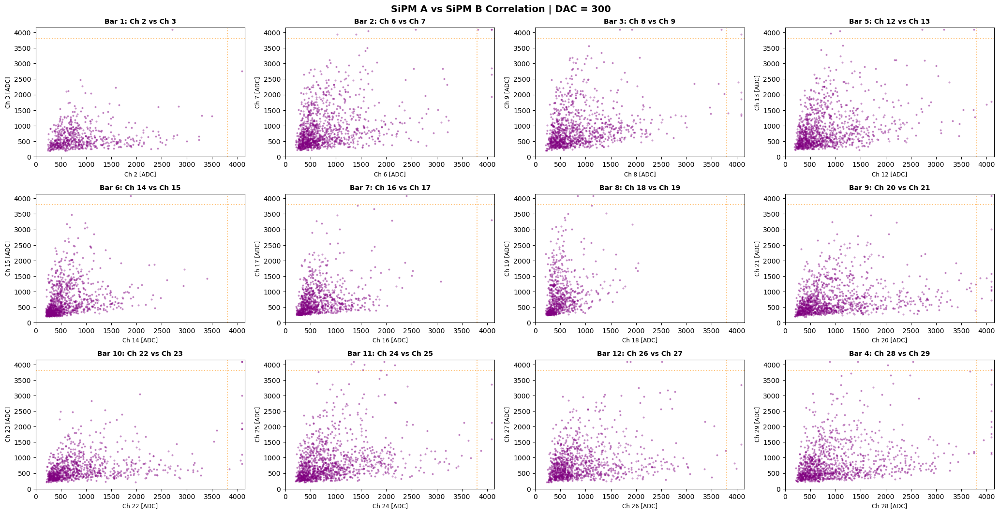


Done! All diagnostic plots and rate reconciliations generated.


In [12]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261112-161522.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # X:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # X:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [1, 4, 5, 11, 30]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    12: {"gain": 10, "bias": 130},
    13: {"gain": 10, "bias": 130},
    14: {"gain": 10, "bias": 130},
    15: {"gain": 10, "bias": 130},
    16: {"gain": 10, "bias": 110},
    17: {"gain": 10, "bias": 110},
    18: {"gain": 10, "bias": 120},
    19: {"gain": 10, "bias": 120},
#     22: {"gain": 11, "bias": 140},
#     22: {"gain": 11, "bias": 140},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)

# CARD 67 (6) - After mech test

Loading data from: /lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261117-115435.h5
Loaded 11,570 events over 31.30 seconds.
Total DAQ Trigger Rate: 369.6 Hz

ELECTRONIC NOISE FROM UNCONNECTED CHANNELS
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Threshold (ADC)     
--------------------------------------------------------------------------------
Ch 1       | 10     | 136.00           | 10.38            | 187.89          
Ch 4       | 10     | 126.00           | 11.86            | 185.30          
Ch 5       | 10     | 123.00           | 11.86            | 182.30          
Ch 11      | 10     | 132.00           | 10.38            | 183.89          
Ch 31      | 10     | 122.00           | 10.38            | 173.89          
--------------------------------------------------------------------------------
--> Median Pedestal = 126.00 ADC
--> Median Sigma = ±10.38 ADC
--> Median Threshold = 183.89 ADC
--> Normalized Electronic Sigma = 1.04 ADC / Gain

Bar   | SiPM A

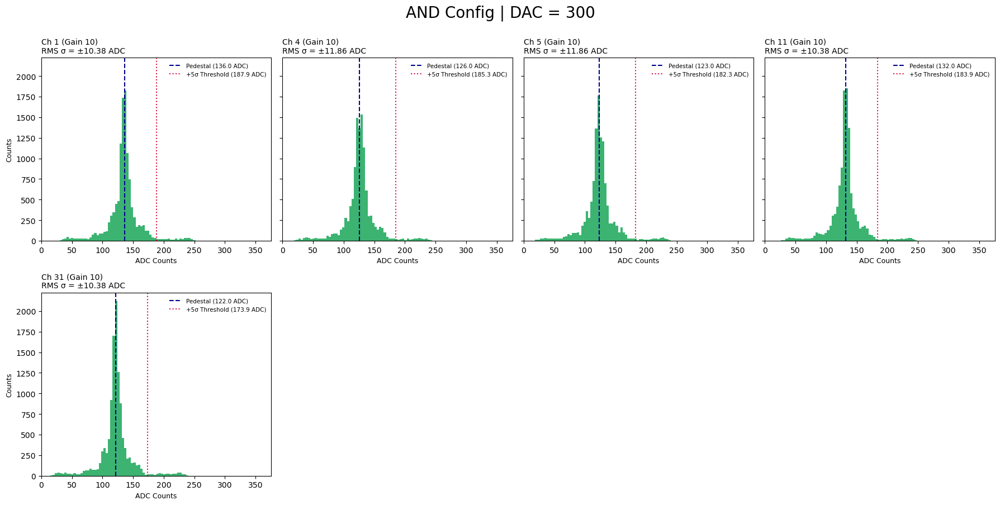

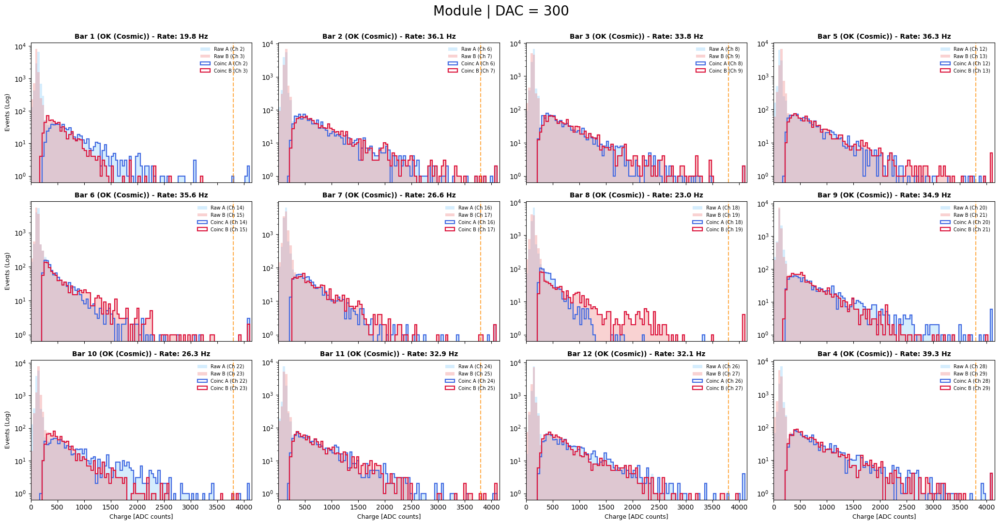

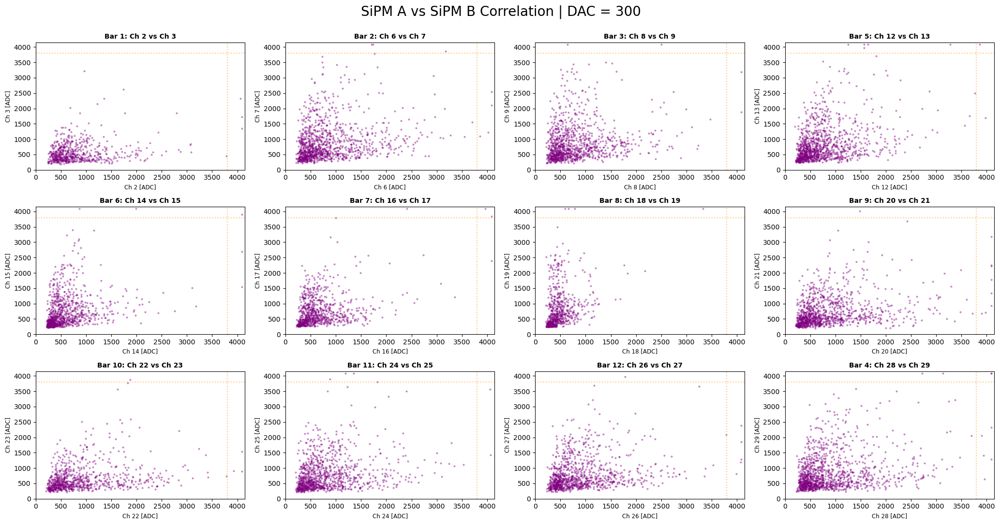


Done! All diagnostic plots and rate reconciliations generated.


In [4]:
FILE_PATH = "/lhome/ific/c/ccortesp/Data/Muon_Veto/02_module/muons_20261117-115435.h5"

BAR_MAP = {
    # X:  (0, 1),
    1:  (2, 3),
    # X:  (4, 5),
    2:  (6, 7),
    3:  (8, 9),
    # 4:  (10, 11),
    5:  (12, 13),
    6:  (14, 15),
    7:  (16, 17),
    8:  (18, 19),
    9: (20, 21),
    10: (22, 23),
    11: (24, 25),
    12: (26, 27),
    4: (28, 29),
    # X: (30, 31)
}

FREE_CHANNELS = [1, 4, 5, 11, 31]
CHANNEL_CONFIG = {ch: {"gain": 10, "bias": 140} for ch in range(32)}
CHANNEL_CONFIG.update({
    12: {"gain": 10, "bias": 130},
    13: {"gain": 10, "bias": 130},
    14: {"gain": 10, "bias": 130},
    15: {"gain": 10, "bias": 130},
    16: {"gain": 10, "bias": 110},
    17: {"gain": 10, "bias": 110},
    18: {"gain": 10, "bias": 120},
    19: {"gain": 10, "bias": 120},
#     22: {"gain": 11, "bias": 140},
#     22: {"gain": 11, "bias": 140},
})
DAC_THRESHOLD = 300

# Run Master Analysis
results = run_veto_analysis(
    file_path=FILE_PATH,
    bar_map=BAR_MAP,
    free_channels=FREE_CHANNELS,
    channel_config=CHANNEL_CONFIG,
    dac_threshold=DAC_THRESHOLD,
    show_noise_plot=True,
    show_spectra_plot=True,
    show_correlation_plot=True
)